# Manipuler des données d'imagerie médicale

In [1]:
import numpy as np
import matplotlib.pyplot as plt
#import  pydicom
#import nibabel as nib
#import SimpleITK as sitk
#import sklearn
import monai

ds = pydicom.dcmread(get_testdata_file("CT_small.dcm"))
#print(ds)
print(ds.)
img = ds.pixel_array.astype(np.float32)
print(img.shape)
plt.imshow(img, cmap='gray')
slope = float(getattr(ds, "RescaleSlope", 1.0))
intercept = float(getattr(ds, "RescaleIntercept", 0.0))


# 3. Lire un volume NIfTI : géométrie et orientation

On telecharge des donnees et on affiche le nombre d'images.

On regarde comment est structure le dataset. 

In [2]:
import monai
data_dir  = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA"
dataset = monai.apps.DecathlonDataset(
    root_dir=data_dir, 
    task="Task09_Spleen", 
    section="training", 
    transform=None, 
    download=True#,  # Télécharge et extrait si non présent
  #  val_frac=0.2    # Réserve 20% pour la validation interne
)


2026-11-02 18:31:59,551 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-11-02 18:31:59,553 - INFO - File exists: /Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen.tar, skipped downloading.
2026-11-02 18:31:59,553 - INFO - Non-empty folder exists in /Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen, skipped extracting.


Loading dataset: 100%|█████████████████████████████████████████████████████████████| 33/33 [00:00<00:00, 367140.67it/s]


In [3]:
print(f"\nnumber of subjects: {len(dataset)}")
print(f"The first element in the dataset is\n{dataset[0]}.")


number of subjects: 33
The first element in the dataset is
{'image': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/imagesTr/spleen_10.nii.gz', 'label': '/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen/labelsTr/spleen_10.nii.gz'}.


In [4]:
# Vérifications
import os
from monai.transforms import LoadImage
from monai.transforms import Orientation
import nibabel as nib



os.chdir("/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen")

loader = LoadImage(image_only=False)
img, meta_img = loader("imagesTr/spleen_10.nii.gz")
mask, meta_mask = loader("labelsTr/spleen_10.nii.gz")



nvImageCodec is not available; skipping pydicom decoder plugin registration.
/Users/valeriemonbet/miniconda3/envs/deep_med/lib/python3.10/site-packages/monai/data/image_reader.py:1166: UserWarning: NvImgCodecPydicomReader: nvImageCodec decoder plugin did not register successfully. Falling back to default pydicom decoders.
  warnings.warn(


In [5]:
meta_img

{'sizeof_hdr': array(348, dtype=int32),
 'extents': array(0, dtype=int32),
 'session_error': array(0, dtype=int16),
 'dim_info': array(0, dtype=uint8),
 'dim': array([  3, 512, 512,  55,   1,   1,   1,   1], dtype=int16),
 'intent_p1': array(0., dtype=float32),
 'intent_p2': array(0., dtype=float32),
 'intent_p3': array(0., dtype=float32),
 'intent_code': array(0, dtype=int16),
 'datatype': array(16, dtype=int16),
 'bitpix': array(32, dtype=int16),
 'slice_start': array(0, dtype=int16),
 'pixdim': array([1.      , 0.976562, 0.976562, 5.      , 0.      , 0.      ,
        0.      , 0.      ], dtype=float32),
 'vox_offset': array(0., dtype=float32),
 'scl_slope': array(nan, dtype=float32),
 'scl_inter': array(nan, dtype=float32),
 'slice_end': array(0, dtype=int16),
 'slice_code': array(0, dtype=uint8),
 'xyzt_units': array(10, dtype=uint8),
 'cal_max': array(0., dtype=float32),
 'cal_min': array(0., dtype=float32),
 'slice_duration': array(0., dtype=float32),
 'toffset': array(0., dtype

In [8]:


meme_forme = img.shape == mask.shape
meme_affine = np.allclose( meta_img["affine"], meta_mask["affine"])
meme_espacement = np.allclose(
    meta_img.get("pixdim")[1:4], meta_mask.get("pixdim")[1:4]
)

print(f"Même forme : {meme_forme}")
print(f"Même affine : {meme_affine}")
print(f"Même espacement : {meme_espacement}")
# 1. Récupérer la matrice affine depuis les métadonnées
affine = meta_img["affine"]
print(affine)

Même forme : True
Même affine : True
Même espacement : True
tensor([[   0.9766,    0.0000,    0.0000, -499.0232],
        [   0.0000,    0.9766,    0.0000, -499.0232],
        [   0.0000,    0.0000,    5.0000,    0.0000],
        [   0.0000,    0.0000,    0.0000,    1.0000]], dtype=torch.float64)


### Orientation

In [9]:

# Réorientation vers le système canonique RAS
reorient = Orientation(axcodes="RAS")
img_canonique = reorient(img)

/Users/valeriemonbet/miniconda3/envs/deep_med/lib/python3.10/site-packages/monai/utils/deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.array Orientation.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)
/Users/valeriemonbet/miniconda3/envs/deep_med/lib/python3.10/site-packages/monai/transforms/spatial/array.py:668: UserWarning: axcodes ('RAS') length is smaller than number of input spatial dimensions D=2.
Orientation: spatial shape = (512, 55), channels = 512,please make sure the input is in the channel-first format.
  warnings.warn(


In [ ]:
### Fonction qui retourne les coordonnées en millimètres d'un voxel

In [ ]:
def voxel_to_world(affine, ijk):
  """Convertit les indices de grille (i, j, k) d'un voxel

  en coordonnées physiques réelles (x, y, z) en millimètres.
  """
  # Passage en coordonnées homogènes (i, j, k, 1)
  ijk_homogeneous = np.array([ijk[0], ijk[1], ijk[2], 1.0])

  # Multiplication matricielle : Affine x IJK_homogeneous
  xyz_homogeneous = np.dot(affine, ijk_homogeneous)

  # On ne garde que les 3 premières coordonnées (x, y, z)
  return xyz_homogeneous[:3]

In [ ]:
voxel_to_world(affine,(1,1,1))

### Fonction de visualisation

In [28]:
def show_slices(vol, spacing=(1, 1, 1), cmap="gray", mask = None, idx = None, **kw):
  """Affiche les trois coupes centrales (axiale, coronale, sagittale)

  côte à côte avec le bon ratio d'aspect basé sur l'espacement des voxels.
  - vol : tableau numpy 3D de forme (X, Y, Z)
  - spacing : tuple (sx, sy, sz) représentant l'espacement des voxels
  """
  nx, ny, nz = vol.shape
  sx, sy, sz = spacing

  # Extraction des indices centraux
  if idx is None:
      idx_x, idx_y, idx_z = nx // 2, ny // 2, nz // 2
  else :
      idx_x, idx_y, idx_z = idx[0], idx[1], idx[2]

  # 1. Coupe Axiale (fixe Z -> plan X, Y)
  axial = vol[:, :, idx_z]
  # 2. Coupe Coronale (fixe Y -> plan X, Z)
  coronal = vol[:, idx_y, :]
  # 3. Coupe Sagittale (fixe X -> plan Y, Z)
  sagittal = vol[idx_x, :, :]

  # Création de la figure avec 3 sous-graphiques
  fig, axes = plt.subplots(1, 3, figsize=(15, 5))

  # Affichage Axial (axes X et Y -> aspect = sx / sy)
  axes[0].imshow(
      axial.T, cmap=cmap, origin="lower", aspect=sy / sx, **kw
  )  # .T pour aligner les axes
  if mask is not None:
      axes[0].imshow(np.ma.masked_where(mask[:, :, idx_z].T == 0, mask[:, :, idx_z].T), cmap="autumn", alpha=0.5,
                      origin="lower", aspect=sy / sx)
  axes[0].set_title(f"Coupe Axiale (Z = {idx_z})")
  axes[0].axis("off")

  # Affichage Coronal (axes X et Z -> aspect = sx / sz)
  axes[1].imshow(coronal.T, cmap=cmap, origin="lower", aspect=sz / sx, **kw)
  if mask is not None:
      axes[1].imshow(np.ma.masked_where(mask[:, idx_y, :].T == 0, mask[:, idx_y, :].T), cmap="autumn", alpha=0.5,
                      origin="lower", aspect=sz / sx)
  axes[1].set_title(f"Coupe Coronale (Y = {idx_y})")
  axes[1].axis("off")

  # Affichage Sagittal (axes Y et Z -> aspect = sy / sz)
  axes[2].imshow(sagittal.T, cmap=cmap, origin="lower", aspect=sz / sy, **kw)
  if mask is not None:
      axes[2].imshow(np.ma.masked_where(mask[idx_x, :, :].T == 0, mask[idx_x, :, :].T), cmap="autumn", alpha=0.5,
                      origin="lower", aspect=sz / sy)
 
  axes[2].set_title(f"Coupe Sagittale (X = {idx_x})")
  axes[2].axis("off")

  plt.tight_layout()
  plt.show()

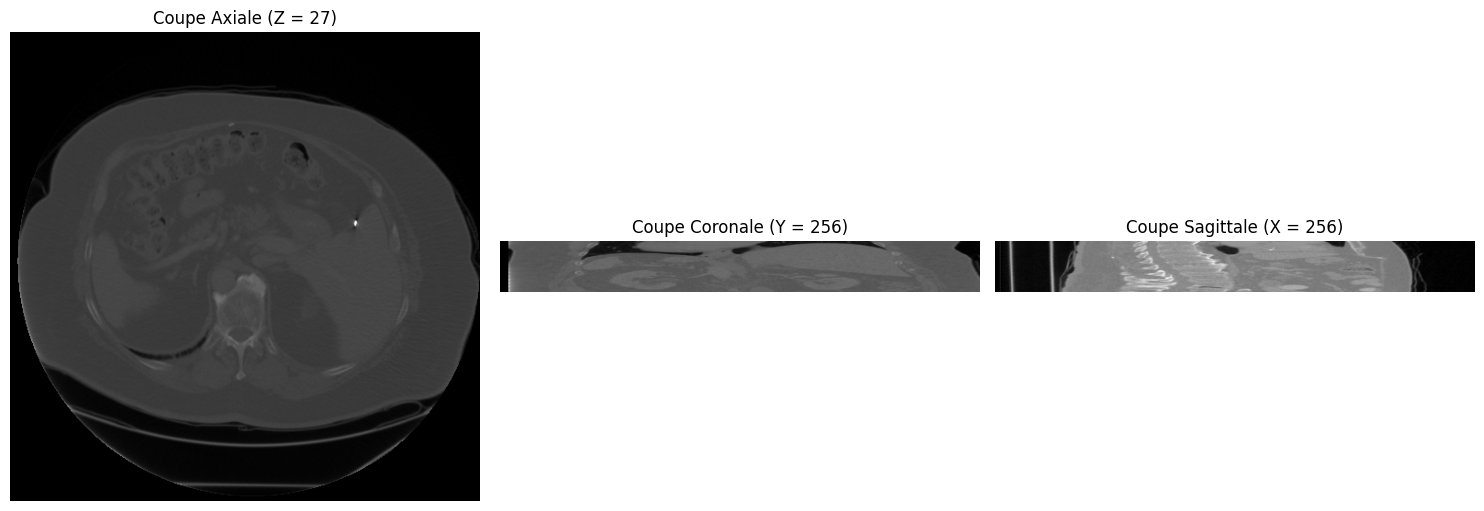

In [26]:
show_slices(img)

[0.976562 0.976562 5.      ]


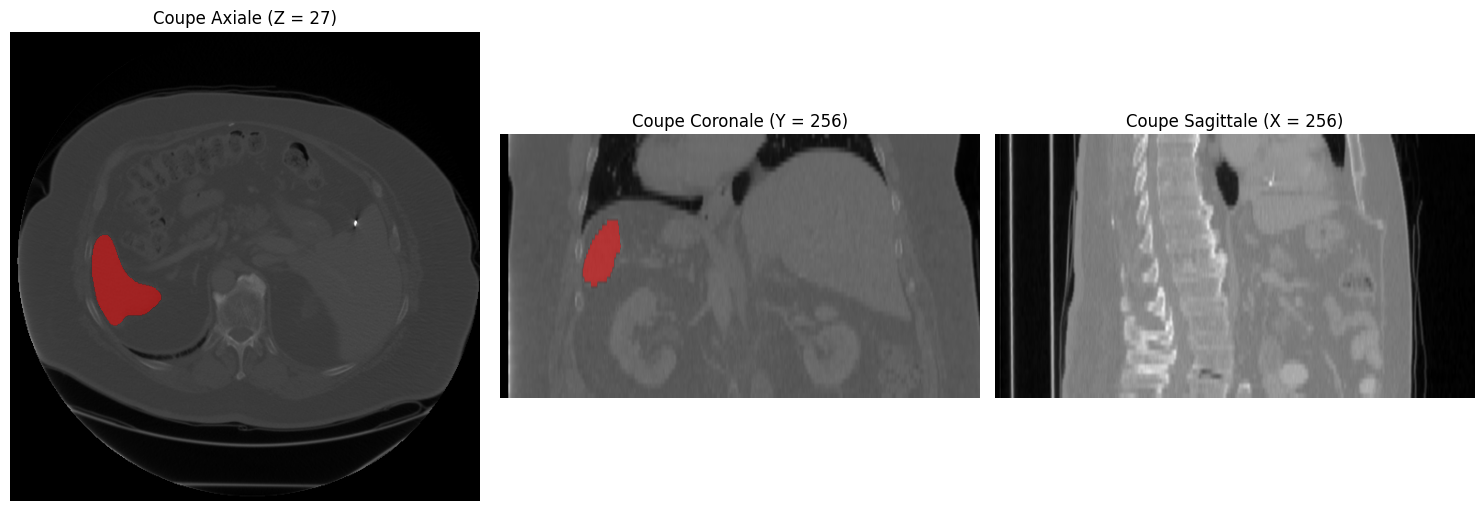

In [29]:
from monai.transforms import Spacing

spc = meta_img.get("pixdim")[1:4]
print(spc)
#image_isotropic = Spacing(pixdim=(1,1,1))(img)
show_slices(img,spacing=spc, mask = mask)

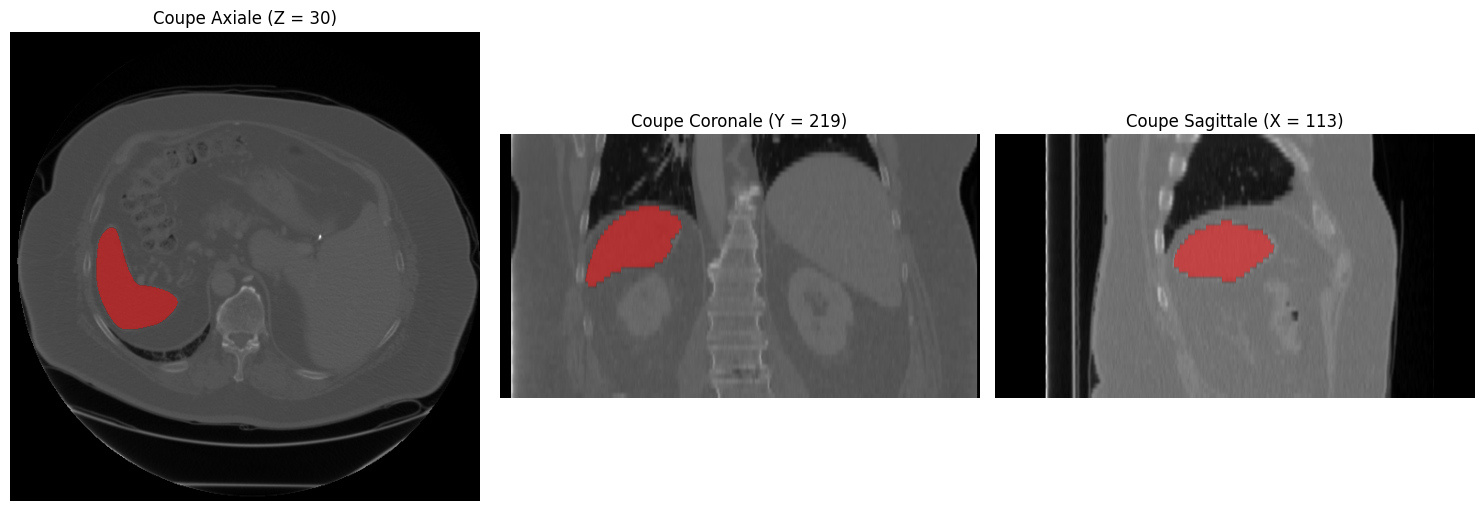

In [33]:
# coupe contenant le maximum de voxels segmentés, dans chaque direction
i_best = int(np.argmax(mask.sum(axis=(1, 2))))
j_best = int(np.argmax(mask.sum(axis=(0, 2))))
k_best = int(np.argmax(mask.sum(axis=(0, 1))))
show_slices(img, spc, mask=mask, idx=[i_best, j_best, k_best])


 Pourquoi est-il dangereux de n'examiner que quelques coupes centrales ?
Un petit organe ou une petite lésion peut ne pas intersecter la coupe centrale : on conclut à tort que le masque est vide ou mal placé (voir le nombre de voxels segmentés ci-dessus). Ici seulement une fraction des coupes contient l'organe.
On ne voit pas les cas atypiques : volumes tronqués, masques vides, artefacts de bord, erreurs d'annotation aux extrémités.
Un contrôle qualité sérieux passe par une vue en mosaïque de toutes les coupes (ou d'une coupe par tranche de  𝑘 ), l'inspection des cas extrêmes (plus grand / plus petit volume, plus grand décalage image-masque) et des statistiques globales sur tout le jeu de données (histogrammes de volumes, d'espacements, d'intensités).
Les biais éventuels du jeu (un seul centre, une seule orientation, des protocoles hétérogènes) sont invisibles sur quelques exemples.

## Normalisation des intensités

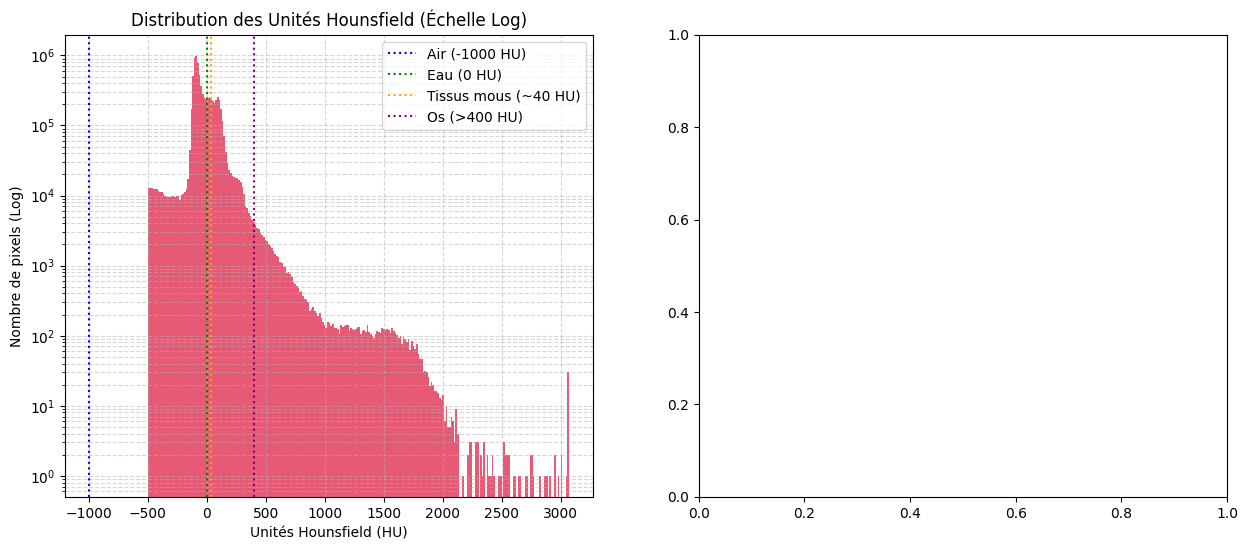

In [42]:
x = img.flatten()
body = x>-500
v = x[body]


fig, ax = plt.subplots(1, 1, figsize=(6, 6))

# Histogramme Log sur l'axe Y
ax[0].hist(v, bins=256, color='crimson', alpha=0.7, log=True)
ax[0].set_title("Distribution des Unités Hounsfield (Échelle Log)")
ax[0].set_xlabel("Unités Hounsfield (HU)")
ax[0].set_ylabel("Nombre de pixels (Log)")
ax[0].grid(True, which="both", ls="--", alpha=0.5)

# Ajout de repères anatomiques sur l'histogramme
ax[0].axvline(x=-1000, color='blue', linestyle=':', label='Air (-1000 HU)')
ax[0].axvline(x=0, color='green', linestyle=':', label='Eau (0 HU)')
ax[0].axvline(x=40, color='orange', linestyle=':', label='Tissus mous (~40 HU)')
ax[0].axvline(x=400, color='purple', linestyle=':', label='Os (>400 HU)')
ax[0].legend()



In [111]:
ct_transforms(sample)

{'image': metatensor([[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]],
 
         [[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]],
 
         [[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]],
 
         ...,
 
         [[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0

nvImageCodec is not available; skipping pydicom decoder plugin registration.


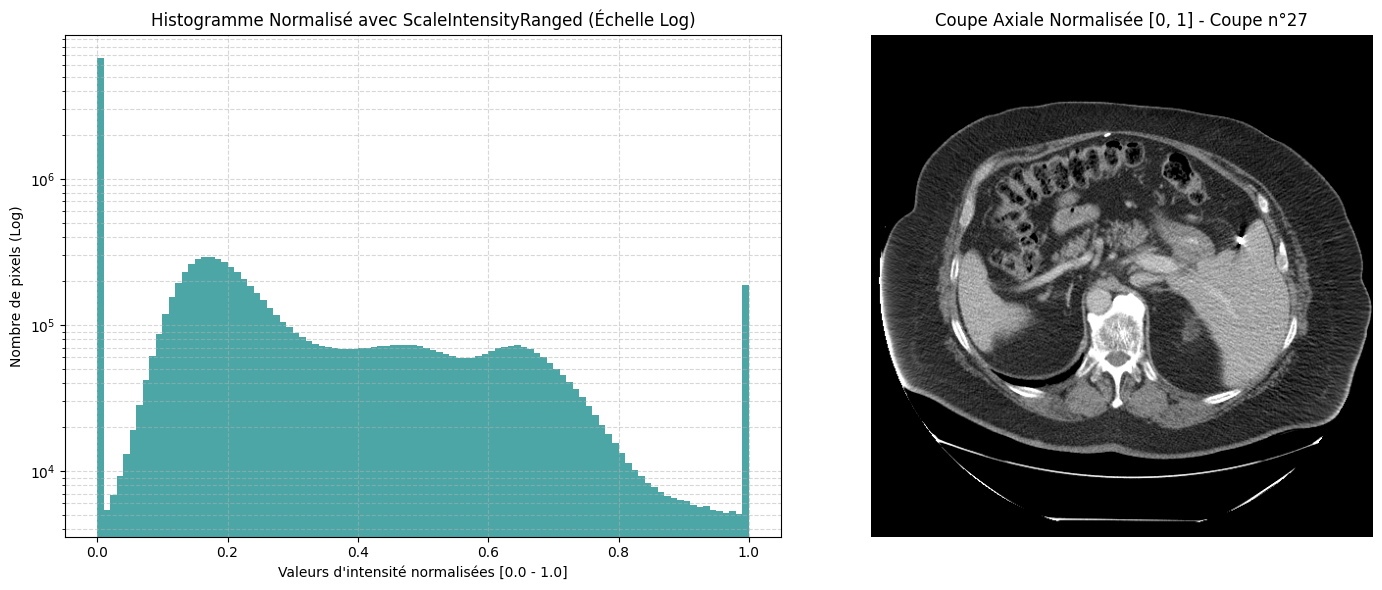

In [112]:
import matplotlib.pyplot as plt
from monai.transforms import LoadImaged, ScaleIntensityRanged, Compose

# 1. Définition du pipeline MONAI avec Normalisation
# Exemple pour les TISSUS MOUS (ex: foie, muscles, cerveau)
# Fenêtre clinique classique : Centre = 40 HU, Largeur = 400 HU
# Donc on garde tout ce qui est entre -160 HU et +240 HU.

ct_transforms = Compose([
    LoadImaged(keys=["image", "label"], reader="ITKReader"),
    ScaleIntensityRanged(
        keys=["image"],
        a_min=-160,          # Borne inférieure en HU
        a_max=240,           # Borne supérieure en HU
        b_min=0.0,           # Nouvelle valeur minimale cible
        b_max=1.0,           # Nouvelle valeur maximale cible
        clip=True            # TRÈS IMPORTANT : Écrase tout ce qui dépasse à 0 et 1
    )
])

# Chargement et transformation
data = {"image": "imagesTr/spleen_10.nii.gz","label":"labelsTr/spleen_10.nii.gz"}
data_dict = ct_transforms(data)

image_tensor = data_dict["image"]
pixel_spacing = image_tensor.meta.get("pixdim")
# Conversion en NumPy 1D pour l'histogramme normalisé
normalized_signals = image_tensor.numpy().flatten()

# 2. Affichage avec Matplotlib
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Histogramme Log des données normalisées [0, 1]
ax[0].hist(normalized_signals, bins=100, color='teal', alpha=0.7, log=True)
ax[0].set_title("Histogramme Normalisé avec ScaleIntensityRanged (Échelle Log)")
ax[0].set_xlabel("Valeurs d'intensité normalisées [0.0 - 1.0]")
ax[0].set_ylabel("Nombre de pixels (Log)")
ax[0].grid(True, which="both", ls="--", alpha=0.5)

# Coupe Axiale (Plus besoin de vmin/vmax car l'image est déjà normalisée !)
slice_idx = image_tensor.shape[-1] // 2
ct_slice = image_tensor[ :, :, slice_idx].numpy()
#aspect_ratio = pixel_spacing / pixel_spacing
ax[1].imshow(ct_slice.T, cmap="gray", origin="lower")
ax[1].set_title(f"Coupe Axiale Normalisée [0, 1] - Coupe n°{slice_idx}")
ax[1].axis("off")

plt.tight_layout()
plt.show()


## Rééchantillonnage

In [71]:
# Liste fictive de vos chemins de fichiers
dataset = [
    {"image": "imagesTr/spleen_10.nii.gz", "label": "labelsTr/spleen_10.nii.gz"},
    {"image": "imagesTr/spleen_12.nii.gz", "label": "labelsTr/spleen_12.nii.gz"},
    {"image": "imagesTr/spleen_13.nii.gz", "label": "labelsTr/spleen_13.nii.gz"},
]

loader = LoadImaged(keys=["image"], reader="ITKReader")
all_spacings = []

for data_dict in dataset:
    loaded_data = loader(data_dict)
    # Extraire pixdim (généralement les indices 1 à 4 pour X, Y, Z dans les métadonnées)
    spacing = loaded_data["image"].meta.get("pixdim")[1:4]
    all_spacings.append(spacing)

# Calcul de la médiane sur chaque axe (X, Y, Z)
median_spacing = np.median(all_spacings, axis=0)
print(f"Espacement médian du dataset : {median_spacing}")

target_spacing = median_spacing.copy()

nvImageCodec is not available; skipping pydicom decoder plugin registration.


Espacement médian du dataset : [0.753906 0.753906 2.5     ]


In [55]:
all_spacings

[array([0.976562, 0.976562, 5.      ], dtype=float32),
 array([0.753906, 0.753906, 1.5     ], dtype=float32),
 array([0.742188, 0.742188, 2.5     ], dtype=float32)]

In [72]:
from monai.transforms import Compose, Spacingd

# Définition du pipeline de rééchantillonnage
resample_transform = Compose([
    LoadImaged(keys=["image", "label"], reader="ITKReader"),
        ScaleIntensityRanged(
        keys=["image"],
        a_min=-160,          # Borne inférieure en HU
        a_max=240,           # Borne supérieure en HU
        b_min=0.0,           # Nouvelle valeur minimale cible
        b_max=1.0,           # Nouvelle valeur maximale cible
        clip=True            # TRÈS IMPORTANT : Écrase tout ce qui dépasse à 0 et 1
    ),
    Spacingd(
        keys=["image", "label"],
        pixdim=target_spacing,
        # Ordre des modes d'interpolation calqué sur l'ordre des keys
        mode=["bilinear", "nearest"], 
        # Mode de gestion des bordures (ex: padding avec des zéros)
        padding_mode="zeros" 
    )
])


sample = dataset[0]
resampled_sample = resample_transform(sample)

print("Nouvelle forme de l'image :", resampled_sample["image"].shape)
print("Nouvel espacement de l'image :", resampled_sample["image"].meta.get("pixdim")[1:4])
print(target_spacing)

nvImageCodec is not available; skipping pydicom decoder plugin registration.


Nouvelle forme de l'image : torch.Size([512, 663, 71])
Nouvel espacement de l'image : [0.753906 0.753906 5.      ]
[0.753906 0.753906 2.5     ]


In [62]:
dataset[0]

{'image': 'imagesTr/spleen_10.nii.gz', 'label': 'labelsTr/spleen_10.nii.gz'}

[0.976562 0.976562 5.      ]


TypeError: string indices must be integers

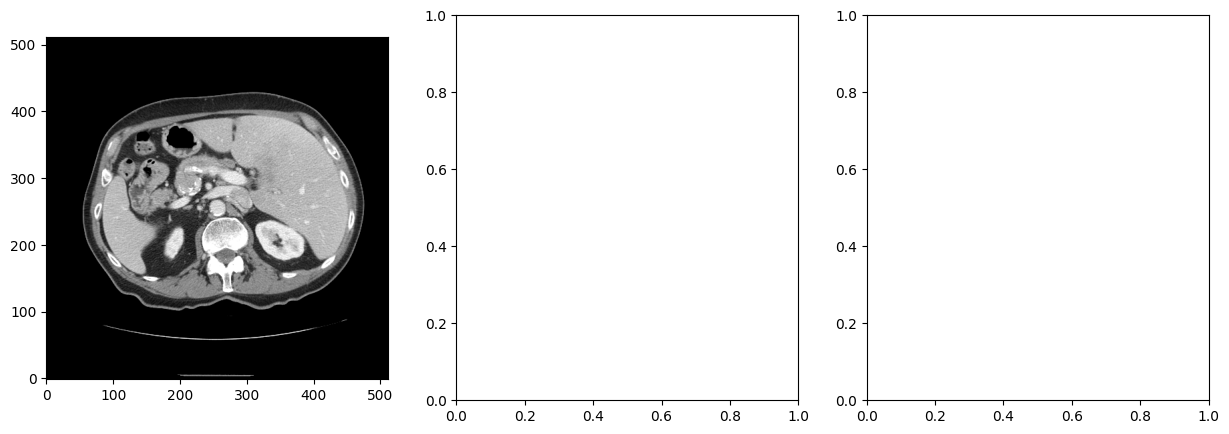

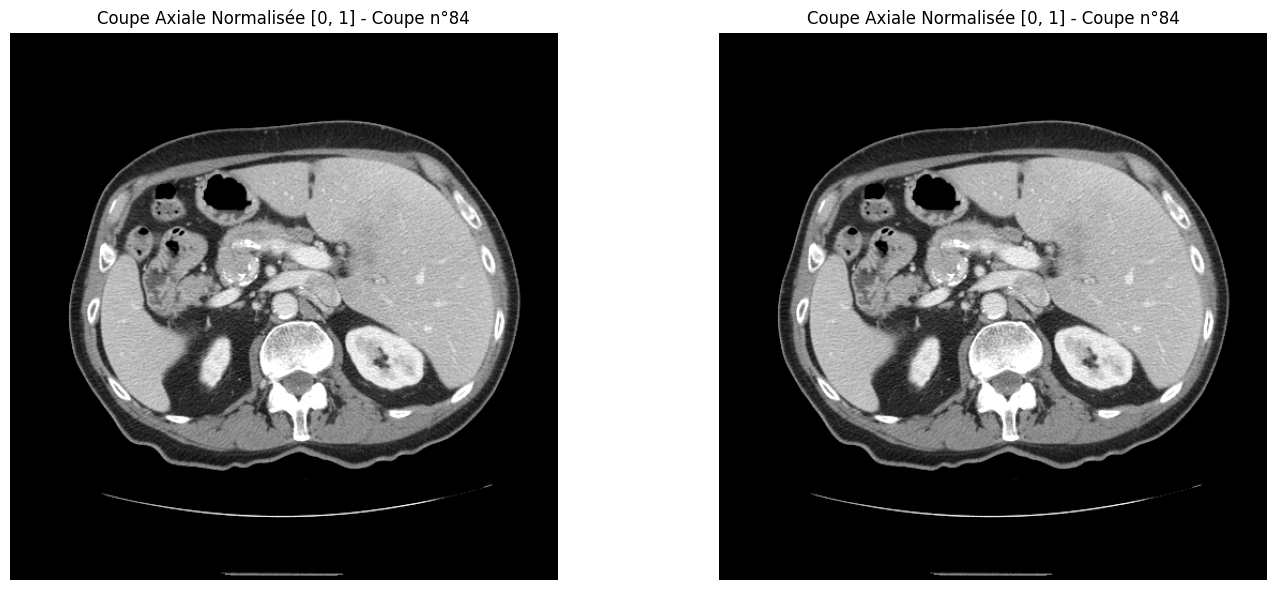

In [113]:
# 2. Affichage avec Matplotlib
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

image_tensor = ct_transforms(sample)["image"]
mask_tensor = ct_transforms(sample)["label"]

# Coupe Axiale 
slice_idx = image_tensor.shape[-1] // 2
ct_slice = image_tensor[ :, :, slice_idx].numpy()
#aspect_ratio = pixel_spacing / pixel_spacing
ax[0].imshow(ct_slice.T, cmap="gray", origin="lower")
ax[0].set_title(f"Coupe Axiale Normalisée [0, 1] - Coupe n°{slice_idx}")
ax[0].axis("off")

image_tensor = resampled_sample["image"]
# Coupe Axiale image interpolee
slice_idx = image_tensor.shape[-1] // 2
ct_slice = image_tensor[ :, :, slice_idx].numpy()
#aspect_ratio = pixel_spacing / pixel_spacing
ax[1].imshow(ct_slice.T, cmap="gray", origin="lower")
ax[1].set_title(f"Coupe Axiale Normalisée [0, 1] - Coupe n°{slice_idx}")
ax[1].axis("off")

plt.tight_layout()
plt.show()


Nouvelle forme de l'image : torch.Size([512, 512, 168])
Nouvel espacement de l'image : [0.753906 0.753906 1.5     ]


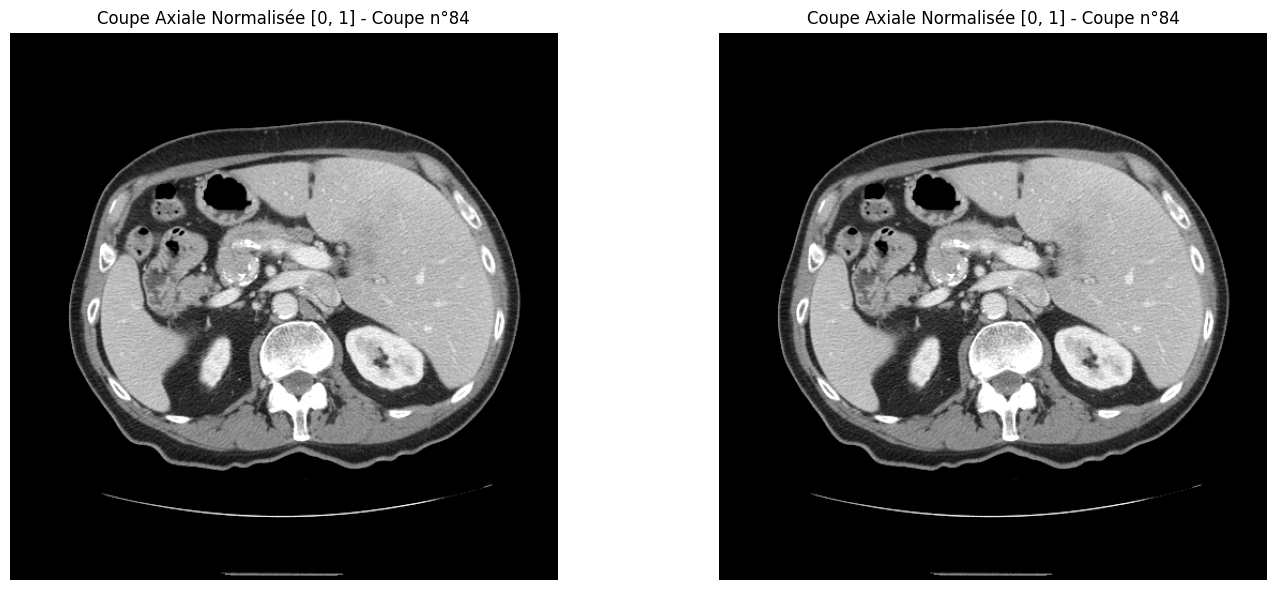

In [74]:
sample = dataset[1]
resampled_sample = resample_transform(sample)

print("Nouvelle forme de l'image :", resampled_sample["image"].shape)
print("Nouvel espacement de l'image :", resampled_sample["image"].meta.get("pixdim")[1:4])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))

image_tensor = ct_transforms(sample)["image"]
# Coupe Axiale 
slice_idx = image_tensor.shape[-1] // 2
ct_slice = image_tensor[ :, :, slice_idx].numpy()
#aspect_ratio = pixel_spacing / pixel_spacing
ax[0].imshow(ct_slice.T, cmap="gray", origin="lower")
ax[0].set_title(f"Coupe Axiale Normalisée [0, 1] - Coupe n°{slice_idx}")
ax[0].axis("off")

image_tensor = resampled_sample["image"]
# Coupe Axiale image interpolee
slice_idx = image_tensor.shape[-1] // 2
ct_slice = image_tensor[ :, :, slice_idx].numpy()
#aspect_ratio = pixel_spacing / pixel_spacing
ax[1].imshow(ct_slice.T, cmap="gray", origin="lower")
ax[1].set_title(f"Coupe Axiale Normalisée [0, 1] - Coupe n°{slice_idx}")
ax[1].axis("off")

plt.tight_layout()
plt.show()

En utilisant la fonciton show_slices

In [108]:
sample

{'image': 'imagesTr/spleen_12.nii.gz', 'label': 'labelsTr/spleen_12.nii.gz'}

[0.976562 0.976562 5.      ]


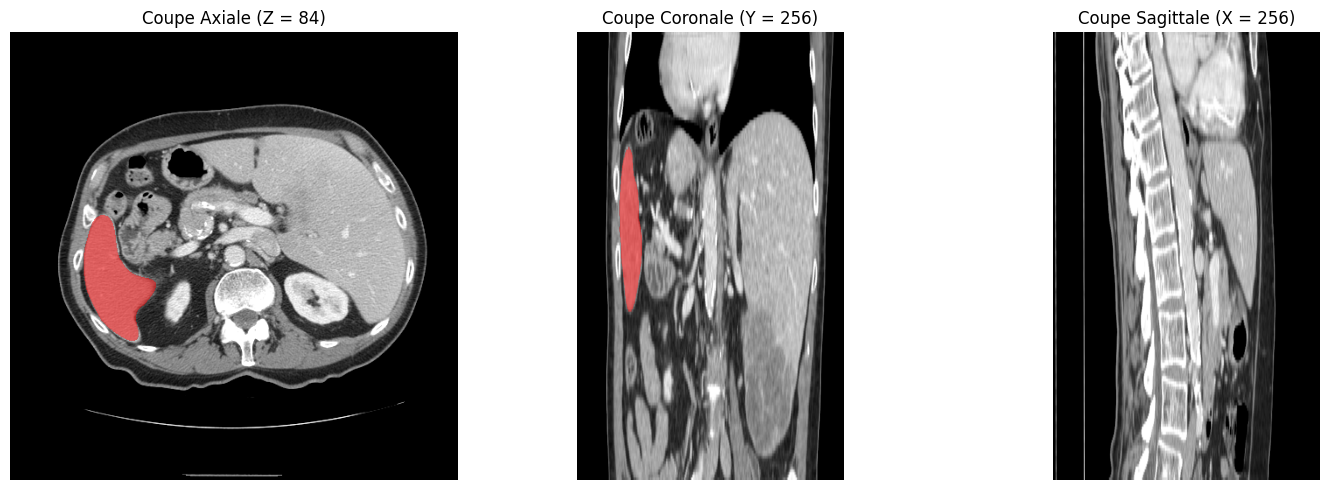

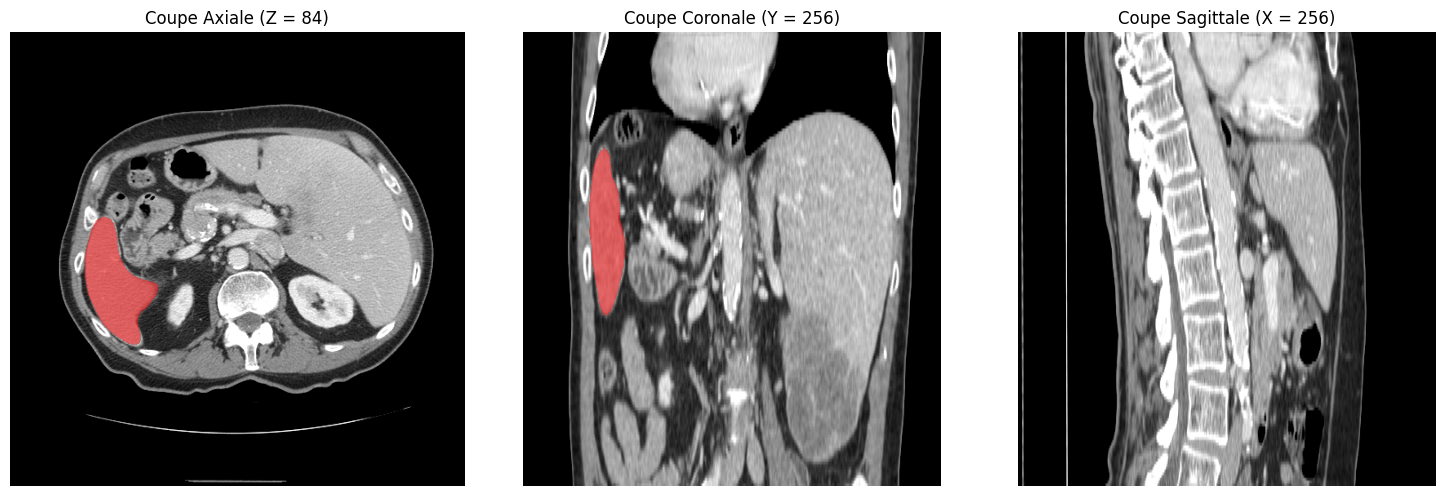

In [115]:
print(spc)
show_slices(vol=image_tensor, spacing=spc,idx=None, mask=mask_tensor)

show_slices(resampled_sample["image"], target_spacing, mask=resampled_sample["label"])



### Interpolation lineaire du mask

In [86]:
mask_interpolated = interpolator(sample)
mask_interpolated["label"]

metatensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]],

         [[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]],

         [[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]],

         ...,

         [[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 

In [87]:
from monai.transforms.spatial.functional import resize
from monai.transforms import Compose, LoadImaged, Resized, ToTensord


# 1. Supposons que 'mask' soit votre tenseur original (ex: shape [H, W, D])
# On s'assure qu'il possède le format channel-first : (Canal, H, W, D) ou (Canal, H, W)
if mask.ndim == 3:  # (H, W, D)
    mask_input = mask.unsqueeze(0) # Ajout de la dimension canal -> (1, H, W, D)
elif mask.ndim == 2:  # (H, W)
    mask_input = mask.unsqueeze(0) # -> (1, H, W)
else:
    mask_input = mask

# 2. Utilisation de la fonction de la bibliothèque avec les bons arguments
# out_size correspond à la taille spatiale cible, et mode='bilinear' ou 'trilinear'
# Pipeline pour un dictionnaire (ex: image et label)
interpolator = Compose([
    LoadImaged(keys=["label"]),
    Resized(
        keys=["label"],
        spatial_size=(128, 128, 32),
        mode=("trilinear"),  # trilinear pour l'image, nearest pour le masque
    ),
    ToTensord(keys=["label"]),
])

mask_interpolated = interpolator(sample) # On repasse en float pour l'interpolation

# Convertir en tableau numpy pour faciliter l'analyse statistique
mask_np = mask_interpolated["label"].detach().cpu().numpy()

# 3. Quelles valeurs apparaissent ?
valeurs_uniques = np.unique(mask_np)
print("Valeurs uniques après interpolation linéaire :")
print(valeurs_uniques)

# 4. Combien de voxels n'ont plus une valeur entière ?
# On compte les éléments dont le modulo par 1 est différent de 0
non_entiers = np.sum(mask_np % 1 != 0)
total_voxels = mask_np.size
pourcentage = (non_entiers / total_voxels) * 100

print(f"Nombre de voxels n'ayant plus une valeur entière : {non_entiers} sur {total_voxels}")
print(f"Soit environ {pourcentage:.2f}% du volume total.")

nvImageCodec is not available; skipping pydicom decoder plugin registration.


Valeurs uniques après interpolation linéaire :
[0.       0.015625 0.03125  0.046875 0.078125 0.09375  0.109375 0.140625
 0.15625  0.171875 0.203125 0.21875  0.234375 0.265625 0.28125  0.296875
 0.328125 0.34375  0.359375 0.390625 0.40625  0.421875 0.453125 0.46875
 0.484375 0.5      0.515625 0.53125  0.546875 0.578125 0.59375  0.609375
 0.640625 0.65625  0.671875 0.703125 0.71875  0.734375 0.765625 0.78125
 0.796875 0.828125 0.84375  0.859375 0.890625 0.90625  0.921875 0.953125
 0.96875  0.984375 1.      ]
Nombre de voxels n'ayant plus une valeur entière : 266688 sur 268435456
Soit environ 0.10% du volume total.


## Train-Test split

In [118]:
import glob, os
import nibabel as nib
import pandas as pd

root = "/Users/valeriemonbet/OneDrive - Université de Rennes/ENSEIGNEMENT/IMAGERIE_MEDICALE/DATA/Task09_Spleen"

rows = []
for img_path in sorted(glob.glob(os.path.join(root, "imagesTr", "*.nii.gz"))):
    name = os.path.basename(img_path)                      # ex : spleen_10.nii.gz
    lab_path = os.path.join(root, "labelsTr", name)
    patient_id = name.replace(".nii.gz", "")               # ex : spleen_10

    img_nii = nib.load(img_path)                           # lecture de l'en-tête (rapide)
    shape = img_nii.shape
    spacing = tuple(float(s) for s in img_nii.header.get_zooms()[:3])

    lab = np.asarray(nib.load(lab_path).dataobj)           # masque (0 = fond, 1 = rate)
    n_vox = int((lab > 0).sum())
    vol_ml = n_vox * np.prod(spacing) / 1000.0             # mm^3 -> mL

    rows.append({
        "patient_id": patient_id,
        "n_coupes": shape[2],
        "espacement_x": spacing[0],
        "espacement_y": spacing[1],
        "espacement_z": spacing[2],
        "volume_organe_ml": vol_ml,
        "image": img_path,
        "label": lab_path,
    })

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(41, 8)


,patient_id,n_coupes,espacement_x,espacement_y,espacement_z,volume_organe_ml,image,label
0,spleen_10,55,0.976562,0.976562,5.0,253.062001,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
1,spleen_12,168,0.753906,0.753906,1.5,458.409483,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
2,spleen_13,77,0.742188,0.742188,2.5,280.796347,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
3,spleen_14,54,0.851562,0.851562,5.0,450.188889,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...
4,spleen_16,61,0.792969,0.792969,8.0,201.437279,/Users/valeriemonbet/OneDrive - Université de ...,/Users/valeriemonbet/OneDrive - Université de ...


In [119]:
from sklearn.model_selection import train_test_split

SEED = 42
patients = df["patient_id"].unique()
train_ids, tmp_ids = train_test_split(patients, test_size=0.4, random_state=SEED)
val_ids, test_ids  = train_test_split(tmp_ids,  test_size=0.5, random_state=SEED)

s_train, s_val, s_test = set(train_ids), set(val_ids), set(test_ids)
assert s_train.isdisjoint(s_val) and s_train.isdisjoint(s_test) and s_val.isdisjoint(s_test)
assert s_train | s_val | s_test == set(patients)